# CurrentSense: Electric Motor Fault Classification

**A comparative study of traditional ML and deep learning for classifying 11 electric motor conditions using current derived measurements.**

**Dataset:** UCI Dataset for Sensorless Drive Diagnosis, 58,509 records, 48 numeric predictors, 11 labels (original file has 49 columns including the target). Source: https://archive.ics.uci.edu/dataset/325/dataset+for+sensorless+drive+diagnosis . DOI: 10.24432/C5VP5F. License: CC BY 4.0.

**Research question:** Do engineered summary features and deeper neural networks improve multiclass motor condition classification compared with classical algorithms? How do these choices affect macro F1, ROC AUC, model size and runtime?

**Methodology:** fixed stratified 70/15/15 train/validation/test; train only preprocessing fitting; 12 predeclared experiments; model selection by validation macro F1; test data evaluated **once after model selection**. Note: source lacks per-run grouping metadata, so a random split may overstate performance on new machines or sessions.

**Integrity:** This notebook never invents outputs. Run all cells to generate real tables, plots, TensorBoard logs and model files. Dataset is downloaded from UCI when the notebook runs, not committed to GitHub.

## 0. Environment and reproducibility

Run in Google Colab with Python 3 and preferably a GPU for neural network experiments. The seed fixes Python, NumPy, scikit-learn and TensorFlow randomness where supported. Some GPU operations can still be nondeterministic.

In [1]:
%pip -q install "numpy>=1.24,<3" "pandas>=2.0,<3" "scikit-learn>=1.4,<2" "matplotlib>=3.7,<4" "joblib>=1.3,<2" "tensorflow>=2.16,<3" "tensorboard>=2.16,<3"

In [2]:
import os, time, json, random, urllib.request, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
    balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_auc_score, roc_curve, auc,
    precision_recall_curve, average_precision_score)
import tensorflow as tf

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

ROOT = Path.cwd()
DATA = ROOT / 'data'
OUTPUTS = ROOT / 'outputs'
MODELS = ROOT / 'models'
LOGS = ROOT / 'logs'
for folder in (DATA, OUTPUTS, MODELS, LOGS): folder.mkdir(parents=True, exist_ok=True)
print('TensorFlow:', tf.__version__, '| GPU available:', bool(tf.config.list_physical_devices('GPU')))

TensorFlow: 2.21.0 | GPU available: True


## 1. Download the authentic source data

Download the original UCI archive. Do not use a replacement synthetic dataset. This cell searches the archive for the `.txt` file, validates that there are exactly 58,509 rows and 49 columns, and saves metadata about the downloaded file. If online download fails, manually upload the original UCI archive or `.txt` into `data/` and run again.

In [3]:
URL = 'https://archive.ics.uci.edu/static/public/325/dataset+for+sensorless+drive+diagnosis.zip'
archive_path = DATA / 'sensorless_drive_uci.zip'
raw_candidates = list(DATA.rglob('*.txt'))
if not raw_candidates:
    if not archive_path.exists():
        try:
            print('Downloading original data from UCI:', URL)
            urllib.request.urlretrieve(URL, archive_path)
        except Exception as exc:
            raise RuntimeError('UCI download failed. Upload the original UCI ZIP or TXT to data/ and rerun.') from exc
    with zipfile.ZipFile(archive_path) as zf:
        safe_items = [item for item in zf.infolist() if item.filename.lower().endswith('.txt')
            and not Path(item.filename).is_absolute() and '..' not in Path(item.filename).parts]
        if not safe_items:
            raise FileNotFoundError('Could not locate a .txt file inside the downloaded UCI archive')
        for item in safe_items:
            out = DATA / Path(item.filename).name
            out.write_bytes(zf.read(item))
    raw_candidates = list(DATA.rglob('*.txt'))

source_path = next((p for p in raw_candidates if 'sensorless' in p.name.lower()), raw_candidates[0])
raw = pd.read_csv(source_path, sep=r'\s+', header=None, engine='c')
assert raw.shape == (58509, 49), f'Unexpected shape {raw.shape}; check original source'
assert raw.iloc[:, -1].nunique() == 11, 'Dataset should have exactly 11 classes'
print('Original file:', source_path)
print('Raw dataset shape:', raw.shape)
display(raw.head())

Original file: /content/data/Sensorless_drive_diagnosis.txt
Raw dataset shape: (58509, 49)


,0,1,2,3,4,5,6,7,8,9,...,39,40,41,42,43,44,45,46,47,48
0,-3.014600e-07,8.260300e-06,-0.000012,-0.000002,-1.438600e-06,-0.000021,0.031718,0.031710,0.031721,-0.032963,...,-0.63308,2.9646,8.1198,-1.4961,-1.4961,-1.4961,-1.4996,-1.4996,-1.4996,1
1,2.913200e-06,-5.247700e-06,0.000003,-0.000006,2.778900e-06,-0.000004,0.030804,0.030810,0.030806,-0.033520,...,-0.59314,7.6252,6.1690,-1.4967,-1.4967,-1.4967,-1.5005,-1.5005,-1.5005,1
2,-2.951700e-06,-3.184000e-06,-0.000016,-0.000001,-1.575300e-06,0.000017,0.032877,0.032880,0.032896,-0.029834,...,-0.63252,2.7784,5.3017,-1.4983,-1.4983,-1.4982,-1.4985,-1.4985,-1.4985,1
3,-1.322600e-06,8.820100e-06,-0.000016,-0.000005,-7.282900e-07,0.000004,0.029410,0.029401,0.029417,-0.030156,...,-0.62289,6.5534,6.2606,-1.4963,-1.4963,-1.4963,-1.4975,-1.4975,-1.4976,1
4,-6.836600e-08,5.666300e-07,-0.000026,-0.000006,-7.940600e-07,0.000013,0.030119,0.030119,0.030145,-0.031393,...,-0.63010,4.5155,9.5231,-1.4958,-1.4958,-1.4958,-1.4959,-1.4959,-1.4959,1


## 2. Exploratory analysis and data limitations

Check missing data, class balance and per-feature distributions. The UCI provider reports that each condition was measured multiple times under 12 operating setups; no independent session identifier is provided. Because the 48 predictors are numerical derived features, avoid claiming a specific physical meaning for any single feature unless independently documented.

Total rows: 58509 | features: 48
Classes: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Missing numerical values: 0
Duplicate full rows: 0 (do not silently remove them)


,count,percent
48,,
1,5319,9.09
2,5319,9.09
3,5319,9.09
4,5319,9.09
5,5319,9.09
6,5319,9.09
7,5319,9.09
8,5319,9.09
9,5319,9.09


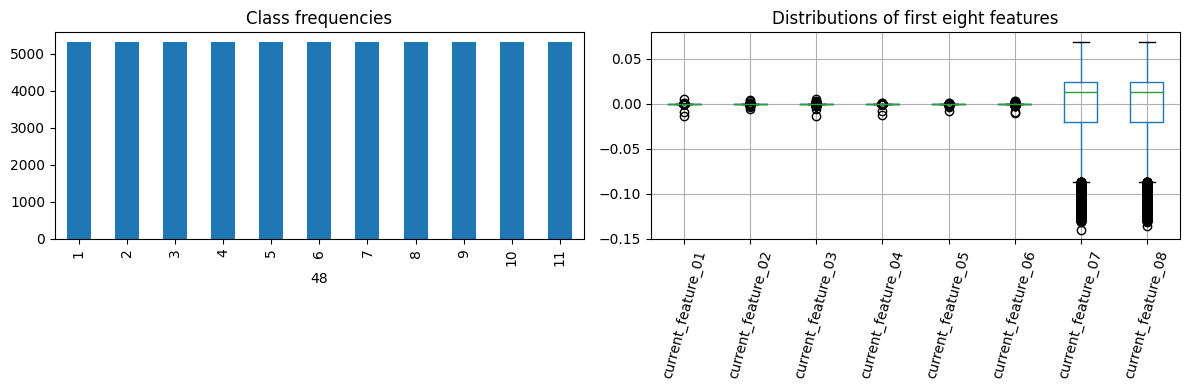

In [4]:
feature_names = [f'current_feature_{i:02d}' for i in range(1, 49)]
X_all = raw.iloc[:, :48].copy()
X_all.columns = feature_names
X_all = X_all.apply(pd.to_numeric, errors='coerce')
y_all = raw.iloc[:, -1].astype(int)
classes = np.sort(y_all.unique())
print('Total rows:', len(raw), '| features:', X_all.shape[1])
print('Classes:', classes.tolist())
print('Missing numerical values:', int(X_all.isna().sum().sum()))
print('Duplicate full rows:', int(raw.duplicated().sum()), '(do not silently remove them)')
display(pd.DataFrame({'count': y_all.value_counts().sort_index(),
    'percent': (100*y_all.value_counts(normalize=True).sort_index()).round(2)}))
fig, axes = plt.subplots(1,2,figsize=(12,4))
y_all.value_counts().sort_index().plot.bar(ax=axes[0], title='Class frequencies')
X_all.iloc[:, :8].boxplot(ax=axes[1], rot=75)
axes[1].set_title('Distributions of first eight features')
plt.tight_layout()
fig.savefig(OUTPUTS/'exploratory_analysis.png', dpi=160)
plt.show()

## 3. Hold out the test set before any experiments

Split into ~70% training, 15% validation and 15% test, stratifying the 11 labels. The final test set is deliberately withheld from tuning, model selection and feature design. This is a *row based split*, not a guarantee of out of session generalization.

In [5]:
X_temp, X_test_raw, y_temp, y_test = train_test_split(
    X_all, y_all, test_size=0.15, random_state=SEED, stratify=y_all)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15/0.85, random_state=SEED, stratify=y_temp)
assert len(set(X_train_raw.index)&set(X_val_raw.index)) == 0
assert len(set(X_train_raw.index)&set(X_test_raw.index)) == 0
assert len(set(X_val_raw.index)&set(X_test_raw.index)) == 0
split_info = {'train':len(X_train_raw),'validation':len(X_val_raw),'test':len(X_test_raw),
              'seed':SEED,'strategy':'stratified row split 70/15/15'}
print(split_info)
(OUTPUTS/'split_info.json').write_text(json.dumps(split_info, indent=2))

{'train': 40955, 'validation': 8777, 'test': 8777, 'seed': 42, 'strategy': 'stratified row split 70/15/15'}


119

## 4. Documented feature engineering

The five engineered features are **row level statistical summaries** of the existing 48 predictors, not additional raw sensor readings. They are designed to test a principled feature augmentation hypothesis. Since original predictors are derived current features, these statistics should not be interpreted as directly measured energy, temperature, or motor damage. All learned preprocessing steps are fitted on training data only.

In [6]:
def engineer_features(frame: pd.DataFrame) -> pd.DataFrame:
    result = frame.copy()
    array = result.to_numpy(dtype=np.float64)
    result['aggregate_abs_mean'] = np.nanmean(np.abs(array), axis=1)
    result['aggregate_std'] = np.nanstd(array, axis=1)
    result['aggregate_negative_share'] = np.nanmean(array < 0, axis=1)
    result['aggregate_range_log'] = np.log1p(np.maximum(0, np.nanmax(array, axis=1) - np.nanmin(array, axis=1)))
    result['aggregate_l2_log'] = np.log1p(np.sqrt(np.nansum(np.square(array), axis=1)))
    return result.replace([np.inf, -np.inf], np.nan)

views = {}
for name, feature_fn in [('raw',lambda x:x.copy()),('engineered',engineer_features)]:
    views[name] = {
      'train':feature_fn(X_train_raw),
      'val':feature_fn(X_val_raw),
      'test':feature_fn(X_test_raw)}
    print(name, views[name]['train'].shape)

def make_preprocess():
    return Pipeline([('imputer',SimpleImputer(strategy='median')),
                     ('scaler',StandardScaler())])

# For reproducibility, model specific pipelines are new for every experiment.
assert views['engineered']['train'].shape[1] == 53

raw (40955, 48)
engineered (40955, 53)


## 5. Evaluation protocol and experiment log

Use **macro F1 as the primary metric** because every condition matters, and report accuracy, macro precision/recall, balanced accuracy and one versus rest macro ROC AUC. A baseline is included to avoid exaggerated interpretations. Predeclared experiment configurations are logged to CSV after each run, alongside runtime and validation metrics. Neural networks also log history to TensorBoard.

In [7]:
def score_multiclass(y_true, preds, proba, class_order):
    measures = {
        'accuracy':accuracy_score(y_true, preds),
        'macro_precision':precision_score(y_true,preds,average='macro',zero_division=0),
        'macro_recall':recall_score(y_true,preds,average='macro',zero_division=0),
        'macro_f1':f1_score(y_true,preds,average='macro',zero_division=0),
        'balanced_accuracy':balanced_accuracy_score(y_true,preds),
    }
    try:
        measures['ovr_roc_auc_macro'] = roc_auc_score(y_true,proba,labels=class_order,
                    average='macro',multi_class='ovr')
    except ValueError:
        measures['ovr_roc_auc_macro'] = np.nan
    return measures

experiments = []
model_registry = {}
validation_probabilities = {}
validation_preds = {}

def log_run(identifier, paradigm, view, params, seconds, scores):
    row = {'experiment':identifier,'paradigm':paradigm,'features':view,
           'settings':json.dumps(params,sort_keys=True), 'train_rows':len(y_train),
           'val_rows':len(y_val),'test_rows_untouched':len(y_test),
           'training_seconds':round(seconds,2),**scores}
    experiments.append(row)
    pd.DataFrame(experiments).to_csv(OUTPUTS/'experiment_results_validation.csv',index=False)
    print(identifier, 'validation macro F1:', round(scores['macro_f1'],4),
          '| accuracy:', round(scores['accuracy'],4), '| seconds:', round(seconds,1))

print('Evaluation functions ready; test data not used.')

Evaluation functions ready; test data not used.


## 6. Traditional machine learning experiments

Run the majority class baseline, logistic regression ablation, random forest ablation, ExtraTrees and gradient boosting. All hyperparameters are deliberately logged so conclusions are traceable to a named run.

Do not select the test set winner. Select only by validation macro F1.

In [8]:
from sklearn.base import clone

traditional_specs = [
  ('B00_Dummy','raw',DummyClassifier(strategy='most_frequent'),{'strategy':'most_frequent'}),
  ('M01_LogReg_Raw','raw',LogisticRegression(C=1.0,max_iter=600,random_state=SEED),{'C':1.0,'max_iter':600}),
  ('M02_LogReg_FeatureAblation','engineered',LogisticRegression(C=1.0,max_iter=600,random_state=SEED),{'C':1.0,'max_iter':600}),
  ('M03_LogReg_Regularized','engineered',LogisticRegression(C=0.2,max_iter=600,random_state=SEED),{'C':0.2,'max_iter':600}),
  ('M04_RF_Raw','raw',RandomForestClassifier(n_estimators=180,max_depth=18,min_samples_leaf=2,n_jobs=-1,random_state=SEED),{'trees':180,'max_depth':18,'min_leaf':2}),
  ('M05_RF_FeatureAblation','engineered',RandomForestClassifier(n_estimators=180,max_depth=18,min_samples_leaf=2,n_jobs=-1,random_state=SEED),{'trees':180,'max_depth':18,'min_leaf':2}),
  ('M06_ExtraTrees','engineered',ExtraTreesClassifier(n_estimators=180,min_samples_leaf=2,n_jobs=-1,random_state=SEED),{'trees':180,'min_leaf':2}),
  ('M07_HistGB','engineered',HistGradientBoostingClassifier(max_iter=140,max_leaf_nodes=31,learning_rate=0.1,random_state=SEED),{'iterations':140,'leaves':31,'lr':0.1}),
  ('M08_HistGB_Tuned','engineered',HistGradientBoostingClassifier(max_iter=180,max_leaf_nodes=21,learning_rate=0.06,random_state=SEED),{'iterations':180,'leaves':21,'lr':0.06}),
]
for name, view, estimator, params in traditional_specs:
    t0=time.perf_counter()
    pipeline=Pipeline([('preprocess',make_preprocess()),('classifier',clone(estimator))])
    pipeline.fit(views[view]['train'], y_train)
    probabilities=pipeline.predict_proba(views[view]['val'])
    preds=pipeline.predict(views[view]['val'])
    score=score_multiclass(y_val,preds,probabilities,pipeline.classes_)
    log_run(name,'traditional',view,params,time.perf_counter()-t0,score)
    model_registry[name]={'model':pipeline,'view':view,'paradigm':'traditional'}
    validation_probabilities[name]=probabilities
    validation_preds[name]=preds

traditional_summary = pd.DataFrame(experiments)
display(traditional_summary.sort_values('macro_f1',ascending=False))

B00_Dummy validation macro F1: 0.0152 | accuracy: 0.0909 | seconds: 0.5
M01_LogReg_Raw validation macro F1: 0.9173 | accuracy: 0.9175 | seconds: 9.8
M02_LogReg_FeatureAblation validation macro F1: 0.9191 | accuracy: 0.9193 | seconds: 10.6
M03_LogReg_Regularized validation macro F1: 0.9091 | accuracy: 0.9095 | seconds: 7.3
M04_RF_Raw validation macro F1: 0.9979 | accuracy: 0.9979 | seconds: 38.5
M05_RF_FeatureAblation validation macro F1: 0.9976 | accuracy: 0.9976 | seconds: 44.4
M06_ExtraTrees validation macro F1: 0.9994 | accuracy: 0.9994 | seconds: 6.5
M07_HistGB validation macro F1: 0.999 | accuracy: 0.999 | seconds: 16.1
M08_HistGB_Tuned validation macro F1: 0.999 | accuracy: 0.999 | seconds: 21.4


,experiment,paradigm,features,settings,train_rows,val_rows,test_rows_untouched,training_seconds,accuracy,macro_precision,macro_recall,macro_f1,balanced_accuracy,ovr_roc_auc_macro
6,M06_ExtraTrees,traditional,engineered,"{""min_leaf"": 2, ""trees"": 180}",40955,8777,8777,6.51,0.999430,0.999431,0.999430,0.999430,0.999430,0.999977
7,M07_HistGB,traditional,engineered,"{""iterations"": 140, ""leaves"": 31, ""lr"": 0.1}",40955,8777,8777,16.11,0.998975,0.998976,0.998975,0.998975,0.998975,0.999997
8,M08_HistGB_Tuned,traditional,engineered,"{""iterations"": 180, ""leaves"": 21, ""lr"": 0.06}",40955,8777,8777,21.36,0.998975,0.998975,0.998975,0.998974,0.998975,0.999998
4,M04_RF_Raw,traditional,raw,"{""max_depth"": 18, ""min_leaf"": 2, ""trees"": 180}",40955,8777,8777,38.50,0.997949,0.997950,0.997949,0.997949,0.997949,0.999986
5,M05_RF_FeatureAblation,traditional,engineered,"{""max_depth"": 18, ""min_leaf"": 2, ""trees"": 180}",40955,8777,8777,44.40,0.997607,0.997608,0.997607,0.997607,0.997607,0.999991
2,M02_LogReg_FeatureAblation,traditional,engineered,"{""C"": 1.0, ""max_iter"": 600}",40955,8777,8777,10.61,0.919335,0.919285,0.919330,0.919114,0.919330,0.994148
1,M01_LogReg_Raw,traditional,raw,"{""C"": 1.0, ""max_iter"": 600}",40955,8777,8777,9.83,0.917512,0.917408,0.917507,0.917287,0.917507,0.994118
3,M03_LogReg_Regularized,traditional,engineered,"{""C"": 0.2, ""max_iter"": 600}",40955,8777,8777,7.28,0.909536,0.909318,0.909532,0.909148,0.909532,0.993389
0,B00_Dummy,traditional,raw,"{""strategy"": ""most_frequent""}",40955,8777,8777,0.53,0.090919,0.008265,0.090909,0.015153,0.090909,0.500000


## 7. Deep learning experiments using TensorFlow `tf.data`

Three fully connected architectures are compared, varying capacity, feature augmentation and regularization. The validation set is used for early stopping. Loss and accuracy histories are saved as genuine output plots and CSVs. When run in Colab, view TensorBoard logs using `%load_ext tensorboard` and `%tensorboard --logdir logs`.

Epoch 1/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.3804 - loss: 1.8307 - val_accuracy: 0.6103 - val_loss: 1.3037
Epoch 2/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6724 - loss: 1.0580 - val_accuracy: 0.7769 - val_loss: 0.7939
Epoch 3/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7857 - loss: 0.7000 - val_accuracy: 0.8559 - val_loss: 0.5563
Epoch 4/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8380 - loss: 0.5287 - val_accuracy: 0.8904 - val_loss: 0.4331
Epoch 5/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8663 - loss: 0.4306 - val_accuracy: 0.9074 - val_loss: 0.3568
Epoch 6/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8869 - loss: 0.3627 - val_accuracy: 0.9253 - val_loss: 0.3069
Epoch 7/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9010 - loss: 0.3171 - val_accuracy: 0.9327 - val_loss: 0.2715
Epoch 8/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9098 - loss: 0.2845 - val_accuracy: 0.

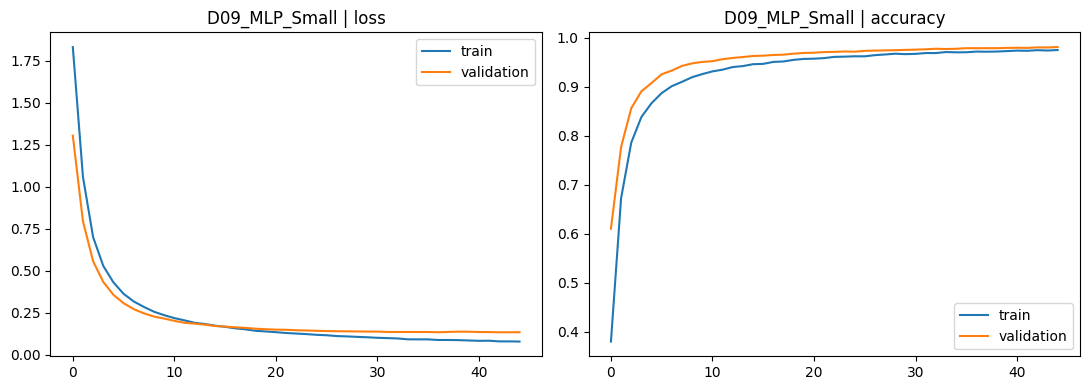

Epoch 1/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.4509 - loss: 1.5227 - val_accuracy: 0.8007 - val_loss: 0.6857
Epoch 2/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7583 - loss: 0.6428 - val_accuracy: 0.8879 - val_loss: 0.3535
Epoch 3/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8392 - loss: 0.4303 - val_accuracy: 0.9275 - val_loss: 0.2533
Epoch 4/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8731 - loss: 0.3464 - val_accuracy: 0.9427 - val_loss: 0.2069
Epoch 5/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8956 - loss: 0.2918 - val_accuracy: 0.9498 - val_loss: 0.1833
Epoch 6/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9078 - loss: 0.2572 - val_accuracy: 0.9581 - val_loss: 0.1653
Epoch 7/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9185 - loss: 0.2285 - val_accuracy: 0.9627 - val_loss: 0.1506
Epoch 8/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9254 - loss: 0.2074 - val_accuracy: 0.

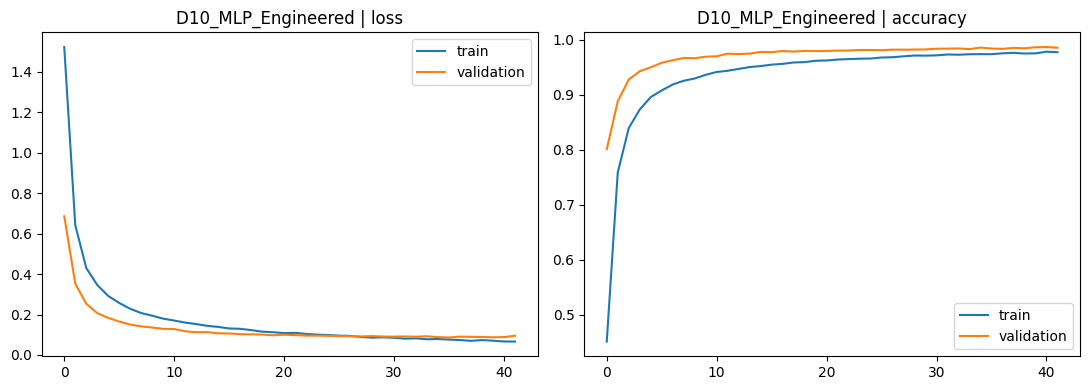

Epoch 1/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.4029 - loss: 1.6500 - val_accuracy: 0.7906 - val_loss: 0.7134
Epoch 2/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7027 - loss: 0.8024 - val_accuracy: 0.8743 - val_loss: 0.4054
Epoch 3/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7951 - loss: 0.5647 - val_accuracy: 0.9068 - val_loss: 0.3144
Epoch 4/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8364 - loss: 0.4711 - val_accuracy: 0.9210 - val_loss: 0.2739
Epoch 5/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8648 - loss: 0.3991 - val_accuracy: 0.9394 - val_loss: 0.2336
Epoch 6/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8831 - loss: 0.3590 - val_accuracy: 0.9469 - val_loss: 0.2088
Epoch 7/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8948 - loss: 0.3291 - val_accuracy: 0.9548 - val_loss: 0.1937
Epoch 8/45
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9071 - loss: 0.3036 - val_accuracy: 0

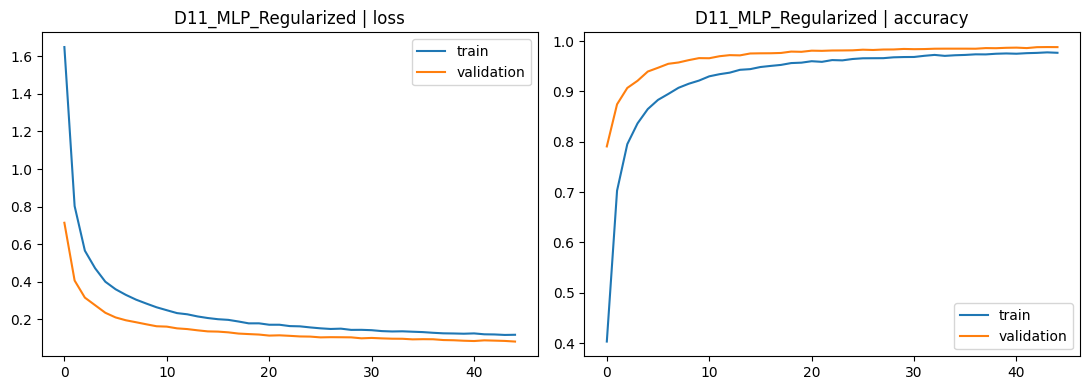

,experiment,paradigm,features,settings,train_rows,val_rows,test_rows_untouched,training_seconds,accuracy,macro_precision,macro_recall,macro_f1,balanced_accuracy,ovr_roc_auc_macro
6,M06_ExtraTrees,traditional,engineered,"{""min_leaf"": 2, ""trees"": 180}",40955,8777,8777,6.51,0.999430,0.999431,0.999430,0.999430,0.999430,0.999977
7,M07_HistGB,traditional,engineered,"{""iterations"": 140, ""leaves"": 31, ""lr"": 0.1}",40955,8777,8777,16.11,0.998975,0.998976,0.998975,0.998975,0.998975,0.999997
8,M08_HistGB_Tuned,traditional,engineered,"{""iterations"": 180, ""leaves"": 21, ""lr"": 0.06}",40955,8777,8777,21.36,0.998975,0.998975,0.998975,0.998974,0.998975,0.999998
4,M04_RF_Raw,traditional,raw,"{""max_depth"": 18, ""min_leaf"": 2, ""trees"": 180}",40955,8777,8777,38.50,0.997949,0.997950,0.997949,0.997949,0.997949,0.999986
5,M05_RF_FeatureAblation,traditional,engineered,"{""max_depth"": 18, ""min_leaf"": 2, ""trees"": 180}",40955,8777,8777,44.40,0.997607,0.997608,0.997607,0.997607,0.997607,0.999991
11,D11_MLP_Regularized,deep learning,engineered,"{""batch_size"": 256, ""dropout"": 0.35, ""early_st...",40955,8777,8777,70.25,0.987923,0.988020,0.987919,0.987918,0.987919,0.999806
10,D10_MLP_Engineered,deep learning,engineered,"{""batch_size"": 256, ""dropout"": 0.25, ""early_st...",40955,8777,8777,52.66,0.983935,0.983999,0.983932,0.983914,0.983932,0.999333
9,D09_MLP_Small,deep learning,raw,"{""batch_size"": 256, ""dropout"": 0.1, ""early_sto...",40955,8777,8777,54.79,0.979948,0.979964,0.979944,0.979932,0.979944,0.998914
2,M02_LogReg_FeatureAblation,traditional,engineered,"{""C"": 1.0, ""max_iter"": 600}",40955,8777,8777,10.61,0.919335,0.919285,0.919330,0.919114,0.919330,0.994148
1,M01_LogReg_Raw,traditional,raw,"{""C"": 1.0, ""max_iter"": 600}",40955,8777,8777,9.83,0.917512,0.917408,0.917507,0.917287,0.917507,0.994118


In [9]:
# Fit one scaler per feature view using ONLY the training split.
tf_views={}
for view in ['raw','engineered']:
    transformer=make_preprocess()
    train_np=transformer.fit_transform(views[view]['train']).astype('float32')
    val_np=transformer.transform(views[view]['val']).astype('float32')
    tf_views[view]={'preprocessor':transformer,'train':train_np,'val':val_np}

class_to_idx={int(label):i for i,label in enumerate(classes)}
y_train_idx=np.array([class_to_idx[int(v)] for v in y_train],dtype=np.int32)
y_val_idx=np.array([class_to_idx[int(v)] for v in y_val],dtype=np.int32)

def build_mlp(input_dim, widths, dropout, l2=0.0, learning_rate=1e-3):
    reg=tf.keras.regularizers.l2(l2) if l2 else None
    net=tf.keras.Sequential([tf.keras.layers.Input(shape=(input_dim,))])
    for width in widths:
        net.add(tf.keras.layers.Dense(width,activation='relu',kernel_regularizer=reg))
        net.add(tf.keras.layers.Dropout(dropout))
    net.add(tf.keras.layers.Dense(len(classes),activation='softmax'))
    net.compile(optimizer=tf.keras.optimizers.Adam(learning_rate),
                loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return net

def make_tf_dataset(x,y,batch_size=256,training=False):
    ds=tf.data.Dataset.from_tensor_slices((x,y))
    if training: ds=ds.shuffle(buffer_size=len(y),seed=SEED,reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

neural_specs=[
  ('D09_MLP_Small','raw',(64,),0.10,0.0,1e-3),
  ('D10_MLP_Engineered','engineered',(128,64),0.25,0.0,1e-3),
  ('D11_MLP_Regularized','engineered',(256,128,64),0.35,1e-4,7e-4),
]
for name, view, widths, dropout, l2, lr in neural_specs:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    spec={'widths':widths,'dropout':dropout,'l2':l2,'learning_rate':lr,
          'batch_size':256,'epochs_max':45,'early_stop_patience':6}
    model=build_mlp(tf_views[view]['train'].shape[1],widths,dropout,l2,lr)
    ds_train=make_tf_dataset(tf_views[view]['train'],y_train_idx,training=True)
    ds_val=make_tf_dataset(tf_views[view]['val'],y_val_idx)
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=6,
                   restore_best_weights=True),
               tf.keras.callbacks.TensorBoard(log_dir=str(LOGS/name),histogram_freq=0)]
    t0=time.perf_counter()
    hist=model.fit(ds_train,validation_data=ds_val,epochs=45,verbose=1,callbacks=callbacks)
    probabilities=model.predict(tf_views[view]['val'],batch_size=512,verbose=0)
    preds=classes[np.argmax(probabilities,axis=1)]
    score=score_multiclass(y_val,preds,probabilities,classes)
    log_run(name,'deep learning',view,spec,time.perf_counter()-t0,score)
    model_registry[name]={'model':model,'view':view,'paradigm':'deep learning',
                          'preprocessor':tf_views[view]['preprocessor']}
    validation_probabilities[name]=probabilities
    validation_preds[name]=preds
    history_frame=pd.DataFrame(hist.history)
    history_frame.to_csv(OUTPUTS/f'{name}_history.csv',index_label='epoch')
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    axes[0].plot(history_frame['loss'],label='train')
    axes[0].plot(history_frame['val_loss'],label='validation')
    axes[0].set_title(name+' | loss'); axes[0].legend()
    axes[1].plot(history_frame['accuracy'],label='train')
    axes[1].plot(history_frame['val_accuracy'],label='validation')
    axes[1].set_title(name+' | accuracy'); axes[1].legend()
    plt.tight_layout();fig.savefig(OUTPUTS/f'{name}_learning_curves.png',dpi=160);plt.show()

experiment_table=pd.DataFrame(experiments).sort_values('macro_f1',ascending=False)
display(experiment_table)

## 8. Compare models and choose the best by validation macro F1

The test set has not influenced this decision. Compare top performers as well as the best traditional model against the best neural network. A higher average score is not automatically better in deployment: runtime, interpretability, motor specificity and cost of an incorrect fault prediction also matter.

Selected models: {'overall': 'M06_ExtraTrees', 'traditional': 'M06_ExtraTrees', 'deep_learning': 'D11_MLP_Regularized', 'criterion': 'validation macro_f1'}


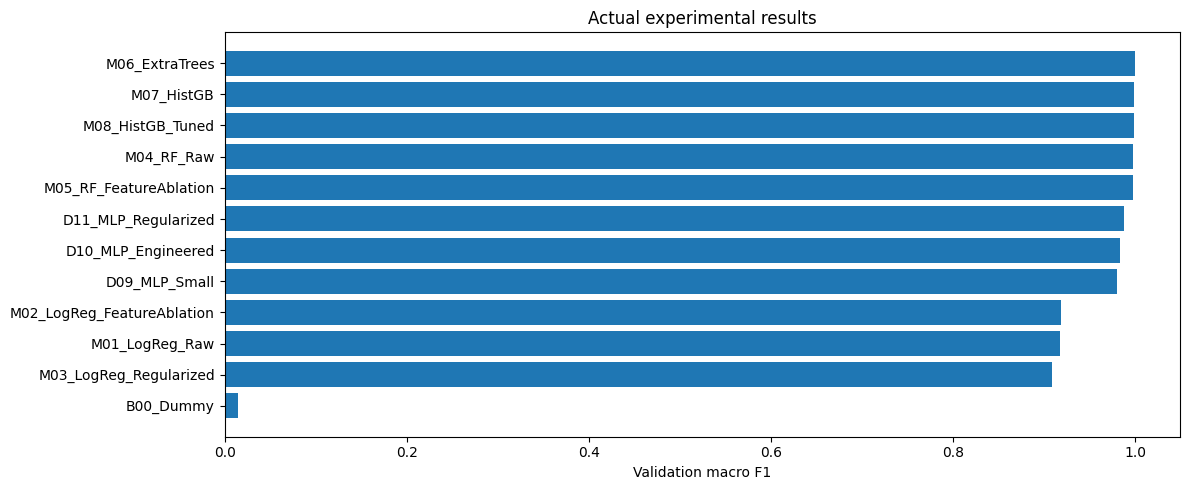

,experiment,paradigm,features,macro_f1,accuracy,ovr_roc_auc_macro,training_seconds,settings
6,M06_ExtraTrees,traditional,engineered,0.999430,0.999430,0.999977,6.51,"{""min_leaf"": 2, ""trees"": 180}"
7,M07_HistGB,traditional,engineered,0.998975,0.998975,0.999997,16.11,"{""iterations"": 140, ""leaves"": 31, ""lr"": 0.1}"
8,M08_HistGB_Tuned,traditional,engineered,0.998974,0.998975,0.999998,21.36,"{""iterations"": 180, ""leaves"": 21, ""lr"": 0.06}"
4,M04_RF_Raw,traditional,raw,0.997949,0.997949,0.999986,38.50,"{""max_depth"": 18, ""min_leaf"": 2, ""trees"": 180}"
5,M05_RF_FeatureAblation,traditional,engineered,0.997607,0.997607,0.999991,44.40,"{""max_depth"": 18, ""min_leaf"": 2, ""trees"": 180}"
11,D11_MLP_Regularized,deep learning,engineered,0.987918,0.987923,0.999806,70.25,"{""batch_size"": 256, ""dropout"": 0.35, ""early_st..."
10,D10_MLP_Engineered,deep learning,engineered,0.983914,0.983935,0.999333,52.66,"{""batch_size"": 256, ""dropout"": 0.25, ""early_st..."
9,D09_MLP_Small,deep learning,raw,0.979932,0.979948,0.998914,54.79,"{""batch_size"": 256, ""dropout"": 0.1, ""early_sto..."
2,M02_LogReg_FeatureAblation,traditional,engineered,0.919114,0.919335,0.994148,10.61,"{""C"": 1.0, ""max_iter"": 600}"
1,M01_LogReg_Raw,traditional,raw,0.917287,0.917512,0.994118,9.83,"{""C"": 1.0, ""max_iter"": 600}"


In [10]:
results = pd.DataFrame(experiments).sort_values('macro_f1',ascending=False)
assert len(results)>=10, 'Not all planned experiments completed'
best_overall=results.iloc[0]['experiment']
best_ml=results.loc[results.paradigm=='traditional'].iloc[0]['experiment']
best_dl=results.loc[results.paradigm=='deep learning'].iloc[0]['experiment']
selection={'overall':best_overall,'traditional':best_ml,'deep_learning':best_dl,
           'criterion':'validation macro_f1'}
(OUTPUTS/'selection.json').write_text(json.dumps(selection,indent=2))
print('Selected models:',selection)
fig,ax=plt.subplots(figsize=(12,5))
sorted_results=results.sort_values('macro_f1')
ax.barh(sorted_results.experiment,sorted_results.macro_f1)
ax.set(xlabel='Validation macro F1',title='Actual experimental results')
plt.tight_layout();fig.savefig(OUTPUTS/'experiment_comparison.png',dpi=180);plt.show()
display(results[['experiment','paradigm','features','macro_f1','accuracy',
                  'ovr_roc_auc_macro','training_seconds','settings']])

## 9. Final test evaluation (run ONCE)

Only now evaluate the preselected winners on the previously untouched test set. This is the final performance estimate for the specified row split.

,experiment,paradigm,accuracy,macro_precision,macro_recall,macro_f1,balanced_accuracy,ovr_roc_auc_macro
0,M06_ExtraTrees,traditional,0.999658,0.999659,0.999658,0.999658,0.999658,1.000000
1,D11_MLP_Regularized,deep learning,0.992252,0.992281,0.992251,0.992250,0.992251,0.999891



CLASSIFICATION REPORT: M06_ExtraTrees
              precision    recall  f1-score   support

           1       1.00      1.00      1.00       798
           2       1.00      1.00      1.00       798
           3       1.00      1.00      1.00       798
           4       1.00      1.00      1.00       798
           5       1.00      1.00      1.00       798
           6       1.00      1.00      1.00       797
           7       1.00      1.00      1.00       798
           8       1.00      1.00      1.00       798
           9       1.00      1.00      1.00       798
          10       1.00      1.00      1.00       798
          11       1.00      1.00      1.00       798

    accuracy                           1.00      8777
   macro avg       1.00      1.00      1.00      8777
weighted avg       1.00      1.00      1.00      8777



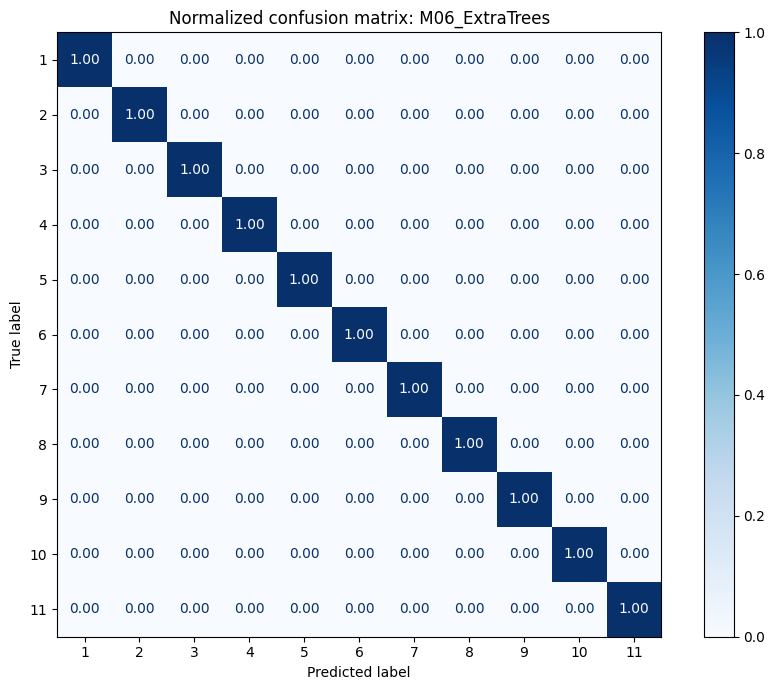


CLASSIFICATION REPORT: D11_MLP_Regularized
              precision    recall  f1-score   support

           1       0.99      1.00      0.99       798
           2       0.98      0.99      0.99       798
           3       1.00      1.00      1.00       798
           4       1.00      1.00      1.00       798
           5       0.99      0.99      0.99       798
           6       0.98      0.98      0.98       797
           7       1.00      1.00      1.00       798
           8       0.99      0.99      0.99       798
           9       0.99      0.98      0.99       798
          10       0.99      0.98      0.99       798
          11       1.00      1.00      1.00       798

    accuracy                           0.99      8777
   macro avg       0.99      0.99      0.99      8777
weighted avg       0.99      0.99      0.99      8777



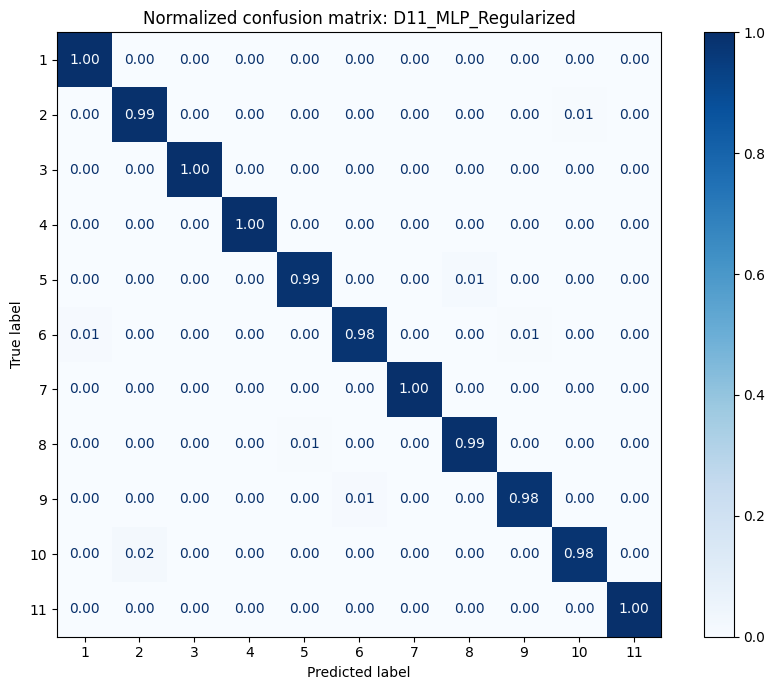

In [11]:
def infer_model(name, input_frame):
    obj=model_registry[name]
    if obj['paradigm']=='traditional':
        p=obj['model'].predict_proba(input_frame)
        pred=obj['model'].predict(input_frame)
    else:
        x=obj['preprocessor'].transform(input_frame).astype('float32')
        p=obj['model'].predict(x,batch_size=512,verbose=0)
        pred=classes[np.argmax(p,axis=1)]
    return pred,p

selected_names=list(dict.fromkeys([best_ml,best_dl,best_overall]))
test_results=[]
test_store={}
for name in selected_names:
    view=model_registry[name]['view']
    preds,p=infer_model(name,views[view]['test'])
    measures=score_multiclass(y_test,preds,p,classes)
    test_results.append({'experiment':name,'paradigm':model_registry[name]['paradigm'],**measures})
    test_store[name]={'preds':preds,'probabilities':p}

test_table=pd.DataFrame(test_results)
test_table.to_csv(OUTPUTS/'final_test_scores.csv',index=False)
display(test_table)
for name in [best_ml,best_dl]:
    print('\nCLASSIFICATION REPORT:',name)
    print(classification_report(y_test,test_store[name]['preds'],zero_division=0))
    labels=classes.astype(str)
    fig,ax=plt.subplots(figsize=(9,7))
    ConfusionMatrixDisplay.from_predictions(y_test,test_store[name]['preds'],
        labels=classes,display_labels=labels,normalize='true',values_format='.2f',ax=ax,cmap='Blues')
    ax.set_title(f'Normalized confusion matrix: {name}')
    fig.tight_layout();fig.savefig(OUTPUTS/f'{name}_confusion_matrix.png',dpi=180);plt.show()

## 10. ROC and precision recall curves

ROC AUC is computed one versus rest for all 11 classes. Display micro pooled and macro aggregated ROC curves for the selected overall model. Per class average precision helps reveal difficult classes. These metrics supplement, not replace, the confusion matrices.

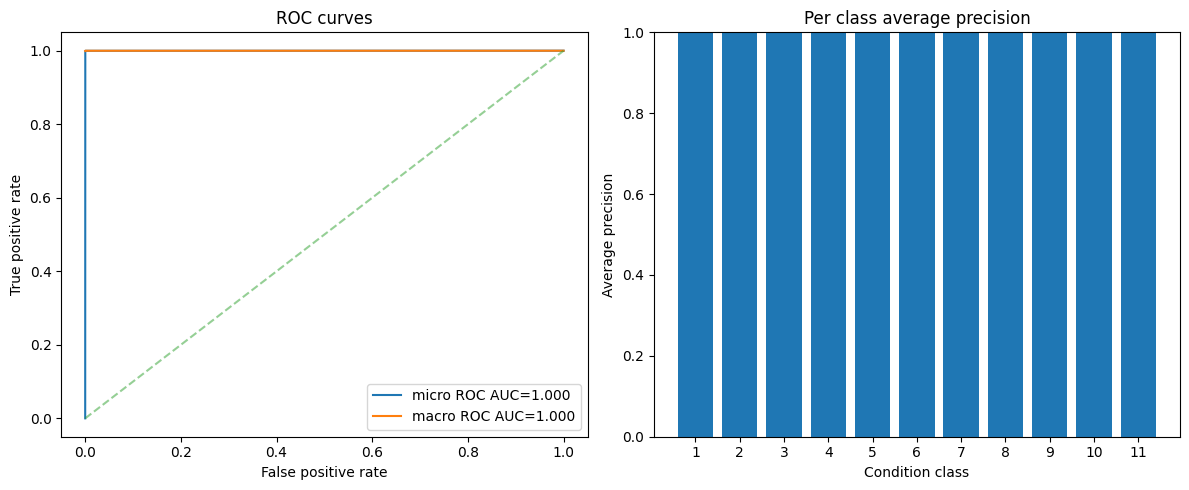

Per-class average precision: {1: 1.0, 2: 0.9999984316234892, 3: 1.0, 4: 1.0, 5: 1.0, 6: 1.0, 7: 1.0, 8: 0.9999999999999999, 9: 0.9999813154756738, 10: 0.9999999999999999, 11: 1.0}


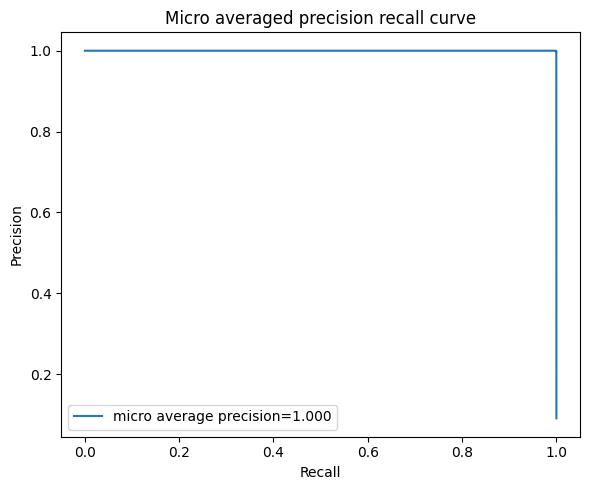

In [12]:
winner=best_overall
preds=test_store[winner]['preds']
proba=test_store[winner]['probabilities']
y_binary=label_binarize(y_test,classes=classes)
fpr_micro,tpr_micro,_=roc_curve(y_binary.ravel(),proba.ravel())
all_fprs=np.unique(np.concatenate([roc_curve(y_binary[:,i],proba[:,i])[0] for i in range(len(classes))]))
mean_tpr=np.zeros_like(all_fprs)
for i in range(len(classes)):
    x,y,_=roc_curve(y_binary[:,i],proba[:,i])
    mean_tpr += np.interp(all_fprs,x,y)
mean_tpr /= len(classes)
fig,axes=plt.subplots(1,2,figsize=(12,5))
axes[0].plot(fpr_micro,tpr_micro,label=f'micro ROC AUC={auc(fpr_micro,tpr_micro):.3f}')
axes[0].plot(all_fprs,mean_tpr,label=f'macro ROC AUC={auc(all_fprs,mean_tpr):.3f}')
axes[0].plot([0,1],[0,1],'--',alpha=.5)
axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC curves')
axes[0].legend()
aps=[average_precision_score(y_binary[:,i],proba[:,i]) for i in range(len(classes))]
axes[1].bar([str(x) for x in classes],aps)
axes[1].set(xlabel='Condition class',ylabel='Average precision',ylim=(0,1),title='Per class average precision')
plt.tight_layout();fig.savefig(OUTPUTS/'roc_and_precision_recall.png',dpi=180);plt.show()
print('Per-class average precision:',dict(zip([int(x) for x in classes],[float(x) for x in aps])))

p_micro,r_micro,_=precision_recall_curve(y_binary.ravel(),proba.ravel())
fig,ax=plt.subplots(figsize=(6,5))
ax.plot(r_micro,p_micro,label=f'micro average precision={average_precision_score(y_binary,proba,average="micro"):.3f}')
ax.set(xlabel='Recall',ylabel='Precision',title='Micro averaged precision recall curve')
ax.legend(loc='lower left');plt.tight_layout()
fig.savefig(OUTPUTS/'micro_precision_recall_curve.png',dpi=180);plt.show()

## 11. Interpret errors and feature contribution carefully

Anonymized features support data driven importance rankings, but they do not identify physical motor components. Report which class pairs are confused most often and which features drive a selected traditional classifier. Interpretability claims need this distinction.

Most common confused class pairs:


,true_class,predicted_class,misclassified_cases
1,9,8,2
0,9,2,1


,feature,importance_mean,importance_std
10,current_feature_11,0.000962,0.000380
7,current_feature_08,0.000816,0.000333
24,current_feature_25,0.000681,0.000193
11,current_feature_12,0.000562,0.000193
18,current_feature_19,0.000542,0.000190
9,current_feature_10,0.000415,0.000009
20,current_feature_21,0.000403,0.000003
12,current_feature_13,0.000273,0.000193
8,current_feature_09,0.000272,0.000192
30,current_feature_31,0.000272,0.000192


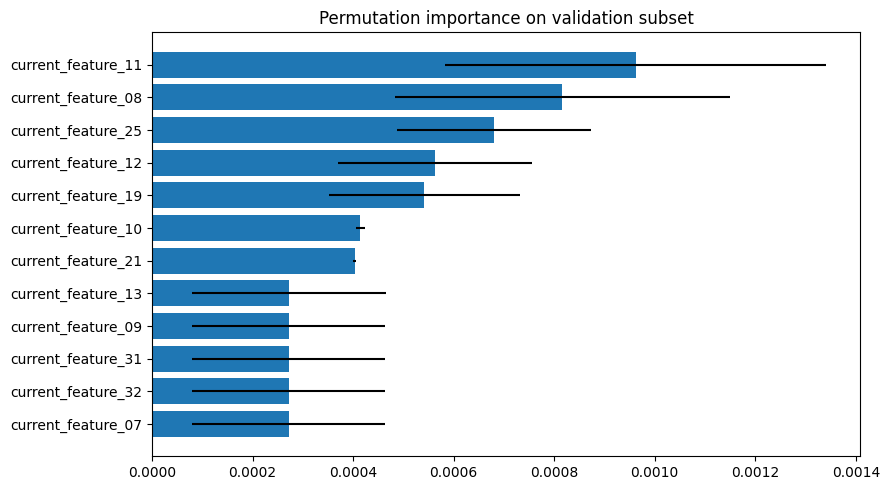

In [13]:
from sklearn.inspection import permutation_importance

winner_pred=test_store[winner]['preds']
cm=confusion_matrix(y_test,winner_pred,labels=classes)
np.fill_diagonal(cm,0)
errors=[]
for i in range(len(classes)):
    for j in range(len(classes)):
        if cm[i,j]>0: errors.append({'true_class':int(classes[i]),'predicted_class':int(classes[j]),
                                     'misclassified_cases':int(cm[i,j])})
error_df=pd.DataFrame(errors).sort_values('misclassified_cases',ascending=False)
error_df.to_csv(OUTPUTS/'class_confusions.csv',index=False)
print('Most common confused class pairs:')
display(error_df.head(10))

ml_obj=model_registry[best_ml]
# Limit to a stratified subset to make repeatable permutation tests tractable.
subset_idx=np.random.RandomState(SEED).choice(len(X_val_raw),size=min(2500,len(X_val_raw)),replace=False)
x_perm=views[ml_obj['view']]['val'].iloc[subset_idx]
y_perm=y_val.iloc[subset_idx]
perm=permutation_importance(ml_obj['model'],x_perm,y_perm,
    n_repeats=3,scoring='f1_macro',random_state=SEED,n_jobs=1)
feature_importance=pd.DataFrame({'feature':x_perm.columns,'importance_mean':perm.importances_mean,
                                 'importance_std':perm.importances_std}).sort_values('importance_mean',ascending=False)
feature_importance.to_csv(OUTPUTS/'feature_importances.csv',index=False)
display(feature_importance.head(15))
fig,ax=plt.subplots(figsize=(9,5))
subset=feature_importance.head(12).iloc[::-1]
ax.barh(subset.feature,subset.importance_mean,xerr=subset.importance_std)
ax.set_title('Permutation importance on validation subset')
plt.tight_layout();fig.savefig(OUTPUTS/'permutation_importance.png',dpi=160);plt.show()

## 12. Learning curve for the traditional model

Training set size curves can diagnose whether more data is likely to improve generalization. Use a logistic baseline, rather than refitting a potentially expensive forest or boosted model many more times. Report both training and validation macro F1; the curves are diagnostic, not another hyperparameter tuning search.

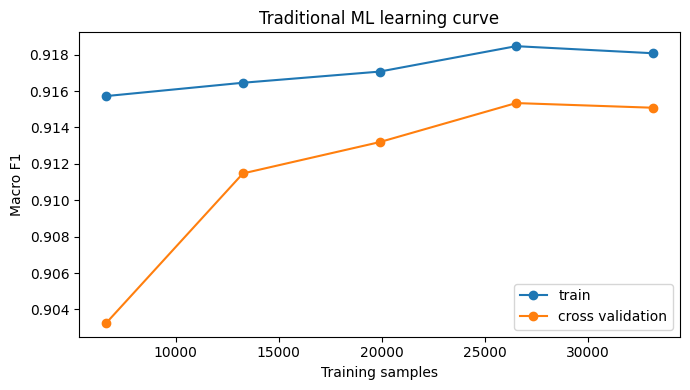

In [14]:
curve_model=Pipeline([('preprocess',make_preprocess()),
                       ('classifier',LogisticRegression(C=1.0,max_iter=600,random_state=SEED))])
X_curve=pd.concat([views['raw']['train'],views['raw']['val']])
y_curve=pd.concat([y_train,y_val])
train_sizes, train_scores, valid_scores=learning_curve(curve_model,X_curve,y_curve,
    cv=3,train_sizes=[.2,.4,.6,.8,1.0],scoring='f1_macro',
    shuffle=True,random_state=SEED,n_jobs=1,error_score='raise')
curve_data=pd.DataFrame({'train_rows':train_sizes,
     'train_macro_f1':train_scores.mean(axis=1),
     'cv_macro_f1':valid_scores.mean(axis=1)})
curve_data.to_csv(OUTPUTS/'traditional_learning_curve.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(train_sizes,train_scores.mean(axis=1),marker='o',label='train')
ax.plot(train_sizes,valid_scores.mean(axis=1),marker='o',label='cross validation')
ax.set(xlabel='Training samples',ylabel='Macro F1',title='Traditional ML learning curve')
ax.legend();plt.tight_layout()
fig.savefig(OUTPUTS/'traditional_learning_curve.png',dpi=160);plt.show()

## 13. Save both best model families and experiment metadata

Save the traditional model as `.joblib`, the Keras model as `.keras`, and its train fitted preprocessor as `.joblib`. Export selection, requirements, model metadata and split information for reproducibility. Place the original UCI archive (zipped) and both best weights files into the submission Google Drive folder.

In [15]:
joblib.dump(model_registry[best_ml]['model'],MODELS/'best_traditional_ml.joblib')
model_registry[best_dl]['model'].save(str(MODELS/'best_deep_learning.keras'))
joblib.dump(model_registry[best_dl]['preprocessor'],MODELS/'deep_learning_preprocessor.joblib')
metadata={'data_source':'https://archive.ics.uci.edu/dataset/325/dataset+for+sensorless+drive+diagnosis',
          'dataset_doi':'10.24432/C5VP5F','n_raw_rows':len(raw),'n_raw_features':48,
          'classes':[int(x) for x in classes],
          'best_ml':best_ml,'best_dl':best_dl,'best_overall':best_overall,
          'ml_features':model_registry[best_ml]['view'],
          'dl_features':model_registry[best_dl]['view'],
          'selection_rule':'max validation macro_f1; test evaluated once',
          'software':{'python':os.sys.version.split()[0],'sklearn':__import__('sklearn').__version__,
                      'tensorflow':tf.__version__}}
(MODELS/'model_metadata.json').write_text(json.dumps(metadata,indent=2))
print('Saved files:')
for f in sorted(MODELS.iterdir()): print(f,round(f.stat().st_size/1e6,2),'MB')

Saved files:
/content/models/best_deep_learning.keras 0.71 MB
/content/models/best_traditional_ml.joblib 90.87 MB
/content/models/deep_learning_preprocessor.joblib 0.0 MB
/content/models/model_metadata.json 0.0 MB


## 14. Evidence based written interpretation


1. Which model won on validation macro F1, and which won among traditional versus deep learning?
2. Does comparing `M01` with `M02` and `M04` with `M05` show that aggregate features genuinely helped?
3. Did the deeper networks generalize better, or exhibit a wider training/validation loss gap?
4. Which motor condition pairs were most frequently confused? What remains unknowable because labels are anonymized?
5. Is the best model's additional training cost justified by its gain over the simplest viable baseline?
6. Can the model be trusted for new operating speeds, environments or motor types? Why is this *not established* by a stratified row split?
7. Cite the original UCI dataset and every externally sourced idea. Do not invent any experimental numbers.


## 14.1 Interpretation of Experimental Results

**1. Which model performed best?**

The Extra Trees classifier (M06) achieved the highest validation macro F1 score of 99.94%, followed by the other tree based models. It also achieved a test accuracy of 99.97%. Among the deep learning models, the Regularized MLP (D11) performed best, achieving 98.79% validation macro F1 and 99.23% test accuracy. These results suggest that the tree based methods were better suited to the classification task in this dataset.

**2. Did feature engineering improve performance?**

Feature engineering had mixed results. Logistic Regression improved from 91.73% to 91.91% validation macro F1 after adding the engineered features. However, Random Forest decreased from 99.79% to 99.76%. Therefore, feature engineering was not consistently beneficial across all algorithms. The original features already contained substantial predictive information.

**3. Did deeper neural networks generalize better?**

The neural network experiments showed an improvement in validation macro F1 from 97.99% for the Small MLP to 98.39% for the Engineered MLP and 98.79% for the Regularized MLP. However, the architectures also differed in their features, dropout rates and regularization settings. Therefore, the improvement cannot be attributed entirely to network depth. The training and validation loss curves should also be examined to determine whether any model experienced overfitting.

**4. Which motor conditions were most frequently confused?**

The Extra Trees classifier made only three incorrect predictions among 8,777 test records. Two observations belonging to class 9 were incorrectly predicted as class 8, while one was predicted as class 2. This suggests that class 9 had the greatest difficulty in the final evaluation. However, since the dataset uses anonymized class labels, the exact physical causes of these classification errors cannot be determined.

**5. Was the additional training cost justified?**

The Extra Trees classifier achieved 99.94% validation macro F1 with approximately 6.5 seconds of training. Logistic Regression achieved 91.73% in approximately 9.8 seconds. In this experiment, Extra Trees achieved both better predictive performance and lower measured training time. The dummy classifier was faster but had a macro F1 of only 1.52%, making it unsuitable as a useful classification model. Training times may vary depending on the hardware and runtime environment.

**6. Can the model be trusted on new motors or operating conditions?**

The results are promising, but generalization to completely new motors or environments has not been demonstrated. The dataset was randomly divided into training, validation and testing subsets. Consequently, similar observations from the same operating conditions might appear across different subsets. Further evaluation using independent motors, operating sessions and environmental conditions would be necessary before considering the model reliable for real industrial deployment.

**7. What sources support the analysis?**

The primary data source is the UCI Sensorless Drive Diagnosis dataset (DOI: 10.24432/C5VP5F). The project also draws on established machine learning methods, including Logistic Regression, Random Forest, Extra Trees, gradient boosting and neural networks. The final report should include appropriate IEEE citations for the dataset and relevant scholarly publications. The performance figures reported here come from the executed notebook experiments.

In [17]:
# Section 15: Model Reliability Checks
# Check exact duplicates and overlapping observations

import pandas as pd

train_features = X_train_raw.reset_index(drop=True)
val_features = X_val_raw.reset_index(drop=True)
test_features = X_test_raw.reset_index(drop=True)

combined_features = pd.concat(
    [train_features, val_features, test_features],
    ignore_index=True
)

duplicate_count = combined_features.duplicated().sum()

def count_overlap(a, b):
  a_keys = set(pd.util.hash_pandas_object(a, index=False))
  b_keys = set(pd.util.hash_pandas_object(b, index=False))
  return len(a_keys.intersection(b_keys))

print("Total duplicate feature rows:", duplicate_count)
print("Train / validation overlap:",
       count_overlap(train_features, val_features))
print("Train / Test overlap:",
      count_overlap(train_features, test_features))
print("Validation / Test overlap:",
      count_overlap(val_features, test_features))

Total duplicate feature rows: 0
Train / validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0


In [20]:
# Cross validation using training and validation data
# The existing test set remains excluded

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.base import clone
import numpy as np

X_cv = pd.concat([
    views["engineered"]["train"],
    views["engineered"]["val"]
])

y_cv = pd.concat([y_train, y_val])

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

model = clone(model_registry[best_ml]["model"])

scores = cross_val_score(
    model,
    X_cv,
    y_cv,
    cv=cv,
    scoring="f1_macro",
    n_jobs=1
)

print("Cross validation macro F1:", scores)
print("Mean macro F1:", scores.mean())
print("Standard deviation:", scores.std())


Cross validation macro F1: [0.99873286 0.99951728 0.99939653]
Mean macro F1: 0.9992155595127694
Standard deviation: 0.0003448601462814909


In [21]:

# Check saved model reproducibility

import joblib
import numpy as np

saved_model = joblib.load(
    MODELS / "best_traditional_ml.joblib"
)

original_predictions = test_store[best_ml]["preds"]

reloaded_predictions = saved_model.predict(
    views[model_registry[best_ml]["view"]]["test"]
)

print(
    "Saved model reproduces original predictions:",
    np.array_equal(original_predictions, reloaded_predictions)
)

print(
    "Matching predictions:",
    np.sum(original_predictions == reloaded_predictions),
    "out of",
    len(original_predictions)
)


Saved model reproduces original predictions: True
Matching predictions: 8777 out of 8777


## 15.1 Model Reliability and Reproducibility Analysis

To investigate the unusually high accuracy of the Extra Trees classifier, I conducted three additional verification checks focusing on duplicate observations, cross validation and saved model reproducibility.

**Duplicate and data overlap analysis:** The dataset contained zero exact duplicate feature rows, and there was no overlap between the training, validation and testing sets. This reduces the concern that identical observations were shared between the datasets. However, it does not rule out similarities between measurements collected under related operating conditions.

**Cross validation analysis:** Three fold stratified cross validation produced macro F1 scores of 0.99873286, 0.99951728 and 0.99939653. The mean macro F1 was 0.99921556, with a standard deviation of approximately 0.00034486. The small variation indicates consistent performance across the three folds and provides additional evidence that the model performs well on different random partitions of the available development data.

**Saved model reproducibility:** After reloading the trained model from its saved file, all 8,777 test predictions matched the original predictions exactly. This confirms that the saved model can reproduce its original outputs in the current environment.

**Overall interpretation:** These checks strengthen confidence in the reported results. The high classification performance does not appear to be explained by exact duplicate observations, and the cross validation results are consistent with the original test performance. Nevertheless, independent evaluation using data from previously unseen motors or operating sessions would still be necessary before claiming reliable performance in real industrial environments.

In [22]:

from google.colab import drive
from pathlib import Path
import shutil

# Connect Google Drive
drive.mount('/content/drive')

# Create project backup folder
backup = Path('/content/drive/MyDrive/CurrentSense_Project')
backup.mkdir(parents=True, exist_ok=True)

# Save models, results and training logs
for folder in [MODELS, OUTPUTS, LOGS]:
    source = Path(folder)
    if source.exists():
        destination = backup / source.name
        shutil.copytree(source, destination, dirs_exist_ok=True)
        print("Saved:", destination)
    else:
        print("Folder not found:", source)

print("Backup completed!")


Mounted at /content/drive
Saved: /content/drive/MyDrive/CurrentSense_Project/models
Saved: /content/drive/MyDrive/CurrentSense_Project/outputs
Saved: /content/drive/MyDrive/CurrentSense_Project/logs
Backup completed!
